# Weighted Cox Model for Imbalanced Survival Data

This notebook implements a **weighted Cox Proportional Hazards model with Lasso (L1) regularization** to handle class imbalance in survival analysis.

## Approach:
- **Lasso (L1) regularization** → Feature selection via sparse coefficients
- **Events get higher weight** (e.g., 5x) → Model focuses more on them
- **Censored observations get lower weight** (e.g., 1x) → But still used
- **No data loss** - all observations contribute to training
- **No synthetic data** - only real patient data

## Advantages over SMOTE/Undersampling:
- ✓ Preserves all survival time information
- ✓ No synthetic data generation
- ✓ Computationally efficient
- ✓ Theoretically sound for Cox models
- ✓ Automatic feature selection via Lasso

In [128]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Survival analysis
from sksurv.linear_model import CoxPHSurvivalAnalysis, CoxnetSurvivalAnalysis
from sksurv.metrics import (
    concordance_index_censored,
    concordance_index_ipcw,
    brier_score,
    cumulative_dynamic_auc,
    integrated_brier_score
)
from sksurv.util import Surv
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# Weighted Cox utilities
import sys
sys.path.append('..')
from functions.weighted_cox import (
    WeightedCoxPH,
    compute_optimal_weights,
    train_weighted_cox_models,
    print_weight_comparison
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print('✓ Libraries loaded successfully')

✓ Libraries loaded successfully


## Load Data

In [129]:
# Load dataset
dataset = pd.read_csv('data/data_treated_nopr.csv')

# Load feature lists
diagnosis_variables = []
with open("data/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("data/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

# Drop unnamed column if exists
if 'Unnamed: 0' in dataset.columns:
    survival_dataset = dataset.drop('Unnamed: 0', axis=1)
else:
    survival_dataset = dataset.copy()

feature_columns = treatment_variables + diagnosis_variables

print(f'Dataset shape: {survival_dataset.shape}')
print(f'Number of features: {len(feature_columns)}')
print(f'  Treatment variables: {len(treatment_variables)}')
print(f'  Diagnosis variables: {len(diagnosis_variables)}')

Dataset shape: (3230, 72)
Number of features: 69
  Treatment variables: 20
  Diagnosis variables: 49


In [130]:
# Handle duplicated patients (same as subsampling approach)
# Find duplicated patients
mask = survival_dataset.duplicated(subset='PERSON_ID', keep=False)

# For each duplicated PERSON_ID, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

print(f'After removing duplicates: {survival_dataset.shape}')
print(f'Removed {len(to_remove)} duplicate rows')

After removing duplicates: (2970, 72)
Removed 260 duplicate rows


In [131]:
# Prepare data in sksurv format
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'].values,
    time=survival_dataset['Survival days'].values
)

print(f'\nData prepared for survival analysis:')
print(f'  Features shape: {data_x.shape}')
print(f'  Samples: {len(data_y)}')
print(f'  Events: {data_y["event"].sum()} ({data_y["event"].mean()*100:.2f}%)')
print(f'  Censored: {(~data_y["event"]).sum()} ({(~data_y["event"]).mean()*100:.2f}%)')
print(f'  Imbalance ratio: 1:{(~data_y["event"]).sum() / data_y["event"].sum():.1f}')


Data prepared for survival analysis:
  Features shape: (2970, 69)
  Samples: 2970
  Events: 33 (1.11%)
  Censored: 2937 (98.89%)
  Imbalance ratio: 1:89.0


## Train-Test Split

In [132]:
# Train-test split using StratifiedKFold (same as subsampling approach)
from sklearn.model_selection import StratifiedKFold

sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=survival_dataset, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

# Create train and test datasets
train = survival_dataset.iloc[train_index].copy()
test = survival_dataset.iloc[test_index].copy()

# Extract features and targets
X_train = train[feature_columns]
X_test = test[feature_columns]

y_train = Surv.from_arrays(
    event=train['Regional LN recurrence'].values.astype(bool),
    time=train['Survival days'].values
)
y_test = Surv.from_arrays(
    event=test['Regional LN recurrence'].values.astype(bool),
    time=test['Survival days'].values
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'  Events:    {y_train["event"].sum()} ({y_train["event"].mean()*100:.2f}%)')
print(f'  Censored:  {(~y_train["event"]).sum()} ({(~y_train["event"]).mean()*100:.2f}%)')

print(f'\nTest set: {X_test.shape[0]} samples')
print(f'  Events:    {y_test["event"].sum()} ({y_test["event"].mean()*100:.2f}%)')
print(f'  Censored:  {(~y_test["event"]).sum()} ({(~y_test["event"]).mean()*100:.2f}%)')

Training set: 2376 samples
  Events:    27 (1.14%)
  Censored:  2349 (98.86%)

Test set: 594 samples
  Events:    6 (1.01%)
  Censored:  588 (98.99%)


## Cross-Validation Evaluation

Perform k-fold cross-validation to evaluate model performance robustly.

In [133]:
# Perform k-fold cross-validation to evaluate baseline Lasso Cox model
print("=" * 60)
print("CROSS-VALIDATION EVALUATION - BASELINE LASSO COX MODEL")
print("=" * 60)

# Initialize CV with same configuration
cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)

# Storage for CV results
cv_results = {
    'fold': [],
    'train_cindex': [],
    'test_cindex': [],
    'test_cindex_ipcw': [],
    'test_ibs': [],
    'n_features': []
}

# Perform CV
for fold_idx, (train_idx, test_idx) in enumerate(cv_eval.split(data_x, survival_dataset['Regional LN recurrence'])):
    print(f"\nFold {fold_idx + 1}/5:")
    
    # Get fold data
    X_train_fold = data_x.iloc[train_idx]
    y_train_fold = data_y[train_idx]
    X_test_fold = data_x.iloc[test_idx]
    y_test_fold = data_y[test_idx]
    
    # Train baseline model (Lasso)
    baseline_fold = CoxnetSurvivalAnalysis(l1_ratio=1.0, fit_baseline_model=True)
    baseline_fold.fit(X_train_fold, y_train_fold)
    
    # Predictions
    train_risk_fold = baseline_fold.predict(X_train_fold)
    test_risk_fold = baseline_fold.predict(X_test_fold)
    
    # Calculate metrics
    train_cindex = concordance_index_censored(
        y_train_fold['event'], y_train_fold['time'], train_risk_fold
    )[0]
    
    test_cindex = concordance_index_censored(
        y_test_fold['event'], y_test_fold['time'], test_risk_fold
    )[0]
    
    # IPCW C-Index
    max_time_fold = min(y_train_fold['time'].max(), y_test_fold['time'].max()) * 0.9
    test_cindex_ipcw = concordance_index_ipcw(
        y_train_fold, y_test_fold, test_risk_fold, tau=max_time_fold
    )[0]
    
    # Integrated Brier Score
    surv_funcs = baseline_fold.predict_survival_function(X_test_fold)
    times = np.array([2*365, 5*365, 10*365])
    times = times[times <= max_time_fold]
    if len(times) > 0:
        pred_surv_probs = np.asarray([[fn(t) for t in times] for fn in surv_funcs])
        test_ibs = integrated_brier_score(y_train_fold, y_test_fold, pred_surv_probs, times)
    else:
        test_ibs = np.nan
    
    # Count non-zero features
    n_features = np.sum(baseline_fold.coef_ != 0)
    
    # Store results
    cv_results['fold'].append(fold_idx + 1)
    cv_results['train_cindex'].append(train_cindex)
    cv_results['test_cindex'].append(test_cindex)
    cv_results['test_cindex_ipcw'].append(test_cindex_ipcw)
    cv_results['test_ibs'].append(test_ibs)
    cv_results['n_features'].append(n_features)
    
    print(f"  Train C-Index: {train_cindex:.4f}")
    print(f"  Test C-Index: {test_cindex:.4f}")
    print(f"  Test IPCW C-Index: {test_cindex_ipcw:.4f}")
    print(f"  Test IBS: {test_ibs:.4f}")
    print(f"  Selected Features: {n_features}")

# Create results DataFrame
cv_results_df = pd.DataFrame(cv_results)

# Calculate summary statistics
print("\n" + "=" * 60)
print("CROSS-VALIDATION SUMMARY")
print("=" * 60)
print(f"Train C-Index: {cv_results_df['train_cindex'].mean():.4f} ± {cv_results_df['train_cindex'].std():.4f}")
print(f"Test C-Index: {cv_results_df['test_cindex'].mean():.4f} ± {cv_results_df['test_cindex'].std():.4f}")
print(f"Test IPCW C-Index: {cv_results_df['test_cindex_ipcw'].mean():.4f} ± {cv_results_df['test_cindex_ipcw'].std():.4f}")
print(f"Test IBS: {cv_results_df['test_ibs'].mean():.4f} ± {cv_results_df['test_ibs'].std():.4f}")
print(f"Average Selected Features: {cv_results_df['n_features'].mean():.1f} ± {cv_results_df['n_features'].std():.1f}")
print(f"Overfitting Gap: {cv_results_df['train_cindex'].mean() - cv_results_df['test_cindex'].mean():.4f}")

# Display full results
print("\nDetailed Results by Fold:")
print(cv_results_df.to_string(index=False))

CROSS-VALIDATION EVALUATION - BASELINE LASSO COX MODEL

Fold 1/5:
  Train C-Index: 0.9458
  Test C-Index: 0.7927
  Test IPCW C-Index: 0.6901
  Test IBS: 0.0283
  Selected Features: 2102

Fold 2/5:
  Train C-Index: 0.9458
  Test C-Index: 0.7927
  Test IPCW C-Index: 0.6901
  Test IBS: 0.0283
  Selected Features: 2102

Fold 2/5:
  Train C-Index: 0.9298
  Test C-Index: 0.9509
  Test IPCW C-Index: 0.9994
  Test IBS: 0.0110
  Selected Features: 2041

Fold 3/5:
  Train C-Index: 0.9298
  Test C-Index: 0.9509
  Test IPCW C-Index: 0.9994
  Test IBS: 0.0110
  Selected Features: 2041

Fold 3/5:
  Train C-Index: 0.9305
  Test C-Index: 0.8485
  Test IPCW C-Index: 0.8072
  Test IBS: 0.0151
  Selected Features: 2189

Fold 4/5:
  Train C-Index: 0.9305
  Test C-Index: 0.8485
  Test IPCW C-Index: 0.8072
  Test IBS: 0.0151
  Selected Features: 2189

Fold 4/5:
  Train C-Index: 0.9596
  Test C-Index: 0.7833
  Test IPCW C-Index: 0.2562
  Test IBS: 0.0323
  Selected Features: 2144

Fold 5/5:
  Train C-Index: 

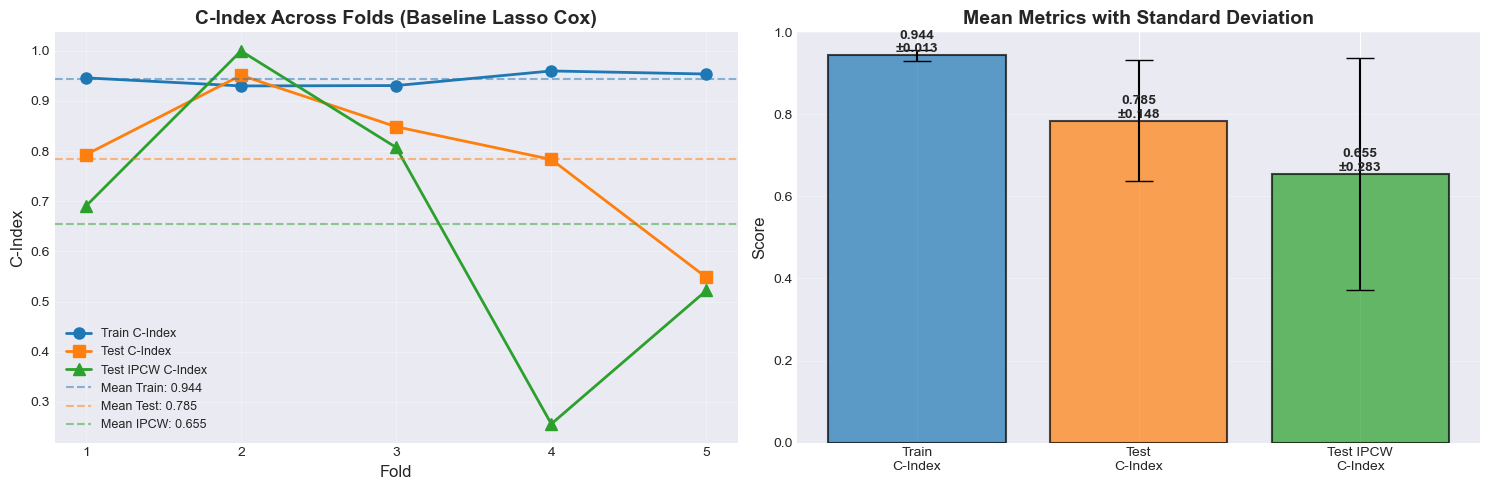


OVERFITTING ANALYSIS
Mean Overfitting Gap: 0.1592 ± 0.1577
Min Gap (Fold 2): -0.0212
Max Gap (Fold 5): 0.4054


In [134]:
# Visualize cross-validation results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: C-Index across folds
ax1 = axes[0]
fold_numbers = cv_results_df['fold']

# Plot train and test C-Index
ax1.plot(fold_numbers, cv_results_df['train_cindex'], 'o-', label='Train C-Index', 
         color='tab:blue', markersize=8, linewidth=2)
ax1.plot(fold_numbers, cv_results_df['test_cindex'], 's-', label='Test C-Index', 
         color='tab:orange', markersize=8, linewidth=2)
ax1.plot(fold_numbers, cv_results_df['test_cindex_ipcw'], '^-', label='Test IPCW C-Index', 
         color='tab:green', markersize=8, linewidth=2)

# Add mean lines
mean_train = cv_results_df['train_cindex'].mean()
mean_test = cv_results_df['test_cindex'].mean()
mean_ipcw = cv_results_df['test_cindex_ipcw'].mean()

ax1.axhline(y=mean_train, color='tab:blue', linestyle='--', alpha=0.5, 
            label=f'Mean Train: {mean_train:.3f}')
ax1.axhline(y=mean_test, color='tab:orange', linestyle='--', alpha=0.5, 
            label=f'Mean Test: {mean_test:.3f}')
ax1.axhline(y=mean_ipcw, color='tab:green', linestyle='--', alpha=0.5, 
            label=f'Mean IPCW: {mean_ipcw:.3f}')

ax1.set_xlabel('Fold', fontsize=12)
ax1.set_ylabel('C-Index', fontsize=12)
ax1.set_title('C-Index Across Folds (Baseline Lasso Cox)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(fold_numbers)

# Plot 2: Metrics comparison with error bars
ax2 = axes[1]
metrics_means = [
    cv_results_df['train_cindex'].mean(),
    cv_results_df['test_cindex'].mean(),
    cv_results_df['test_cindex_ipcw'].mean()
]
metrics_stds = [
    cv_results_df['train_cindex'].std(),
    cv_results_df['test_cindex'].std(),
    cv_results_df['test_cindex_ipcw'].std()
]
metric_labels = ['Train\nC-Index', 'Test\nC-Index', 'Test IPCW\nC-Index']

bars = ax2.bar(metric_labels, metrics_means, yerr=metrics_stds, 
               capsize=10, alpha=0.7, color=['tab:blue', 'tab:orange', 'tab:green'],
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, mean, std in zip(bars, metrics_means, metrics_stds):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{mean:.3f}\n±{std:.3f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.set_ylabel('Score', fontsize=12)
ax2.set_title('Mean Metrics with Standard Deviation', fontsize=14, fontweight='bold')
ax2.set_ylim(0, 1)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Additional plot: Overfitting gap
print("\n" + "=" * 60)
print("OVERFITTING ANALYSIS")
print("=" * 60)
gap_per_fold = cv_results_df['train_cindex'] - cv_results_df['test_cindex']
print(f"Mean Overfitting Gap: {gap_per_fold.mean():.4f} ± {gap_per_fold.std():.4f}")
print(f"Min Gap (Fold {gap_per_fold.idxmin() + 1}): {gap_per_fold.min():.4f}")
print(f"Max Gap (Fold {gap_per_fold.idxmax() + 1}): {gap_per_fold.max():.4f}")

### Cross-Validation for Weighted Models

Now evaluate weighted Cox models across all folds to find the best weight configuration robustly.

In [135]:
# Cross-validation for weighted models
print("=" * 60)
print("CROSS-VALIDATION - WEIGHTED COX MODELS")
print("=" * 60)

# Test different weight configurations
weight_configs = [1, 2, 3, 5, 10]

# Storage for weighted CV results
weighted_cv_results = {config: {'train_cindex': [], 'test_cindex': [], 'test_cindex_ipcw': []} 
                       for config in weight_configs}

# Perform CV
cv_eval_weighted = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)

for fold_idx, (train_idx, test_idx) in enumerate(cv_eval_weighted.split(data_x, survival_dataset['Regional LN recurrence'])):
    print(f"\nFold {fold_idx + 1}/5:")
    
    # Get fold data
    X_train_fold = data_x.iloc[train_idx]
    y_train_fold = data_y[train_idx]
    X_test_fold = data_x.iloc[test_idx]
    y_test_fold = data_y[test_idx]
    
    # Test each weight configuration
    for weight_config in weight_configs:
        # Train weighted model (event_weight is set during initialization)
        weighted_model = WeightedCoxPH(event_weight=weight_config, l1_ratio=1.0)
        weighted_model.fit(X_train_fold, y_train_fold)
        
        # Predictions
        train_risk = weighted_model.predict(X_train_fold)
        test_risk = weighted_model.predict(X_test_fold)
        
        # Calculate metrics
        train_cindex = concordance_index_censored(
            y_train_fold['event'], y_train_fold['time'], train_risk
        )[0]
        
        test_cindex = concordance_index_censored(
            y_test_fold['event'], y_test_fold['time'], test_risk
        )[0]
        
        # IPCW C-Index
        max_time_fold = min(y_train_fold['time'].max(), y_test_fold['time'].max()) * 0.9
        test_cindex_ipcw = concordance_index_ipcw(
            y_train_fold, y_test_fold, test_risk, tau=max_time_fold
        )[0]
        
        # Store results
        weighted_cv_results[weight_config]['train_cindex'].append(train_cindex)
        weighted_cv_results[weight_config]['test_cindex'].append(test_cindex)
        weighted_cv_results[weight_config]['test_cindex_ipcw'].append(test_cindex_ipcw)
    
    print(f"  Completed all weight configurations for fold {fold_idx + 1}")

# Create summary DataFrame
weighted_summary = []
for config in weight_configs:
    results = weighted_cv_results[config]
    weighted_summary.append({
        'Weight': f'{config}x',
        'Train C-Index': f"{np.mean(results['train_cindex']):.4f} ± {np.std(results['train_cindex']):.4f}",
        'Test C-Index': f"{np.mean(results['test_cindex']):.4f} ± {np.std(results['test_cindex']):.4f}",
        'Test IPCW': f"{np.mean(results['test_cindex_ipcw']):.4f} ± {np.std(results['test_cindex_ipcw']):.4f}",
        'Mean Test C-Index': np.mean(results['test_cindex']),
        'Overfitting Gap': np.mean(results['train_cindex']) - np.mean(results['test_cindex'])
    })

weighted_summary_df = pd.DataFrame(weighted_summary)

print("\n" + "=" * 60)
print("WEIGHTED MODELS CV SUMMARY")
print("=" * 60)
print(weighted_summary_df[['Weight', 'Train C-Index', 'Test C-Index', 'Test IPCW']].to_string(index=False))

# Find best configuration
best_config_idx = weighted_summary_df['Mean Test C-Index'].idxmax()
best_config = weighted_summary_df.iloc[best_config_idx]

print("\n" + "=" * 60)
print("BEST CONFIGURATION")
print("=" * 60)
print(f"Best Weight Configuration: {best_config['Weight']}")
print(f"Train C-Index: {best_config['Train C-Index']}")
print(f"Test C-Index: {best_config['Test C-Index']}")
print(f"Test IPCW C-Index: {best_config['Test IPCW']}")
print(f"Overfitting Gap: {best_config['Overfitting Gap']:.4f}")

# Compare with baseline
baseline_mean = cv_results_df['test_cindex'].mean()
improvement = best_config['Mean Test C-Index'] - baseline_mean
print(f"\nImprovement over Baseline: {improvement:.4f} ({improvement/baseline_mean*100:+.2f}%)")

CROSS-VALIDATION - WEIGHTED COX MODELS

Fold 1/5:
  Completed all weight configurations for fold 1

Fold 2/5:
  Completed all weight configurations for fold 1

Fold 2/5:
  Completed all weight configurations for fold 2

Fold 3/5:
  Completed all weight configurations for fold 2

Fold 3/5:
  Completed all weight configurations for fold 3

Fold 4/5:
  Completed all weight configurations for fold 3

Fold 4/5:
  Completed all weight configurations for fold 4

Fold 5/5:
  Completed all weight configurations for fold 4

Fold 5/5:
  Completed all weight configurations for fold 5

WEIGHTED MODELS CV SUMMARY
Weight   Train C-Index    Test C-Index       Test IPCW
    1x 0.8460 ± 0.0657 0.7428 ± 0.1175 0.6005 ± 0.2458
    2x 0.8463 ± 0.0663 0.7386 ± 0.1188 0.5975 ± 0.2458
    3x 0.8467 ± 0.0666 0.7364 ± 0.1191 0.5940 ± 0.2457
    5x 0.8048 ± 0.0842 0.7227 ± 0.1204 0.6137 ± 0.2504
   10x 0.8712 ± 0.0518 0.7557 ± 0.1321 0.6259 ± 0.2684

BEST CONFIGURATION
Best Weight Configuration: 10x
Train C-Inde

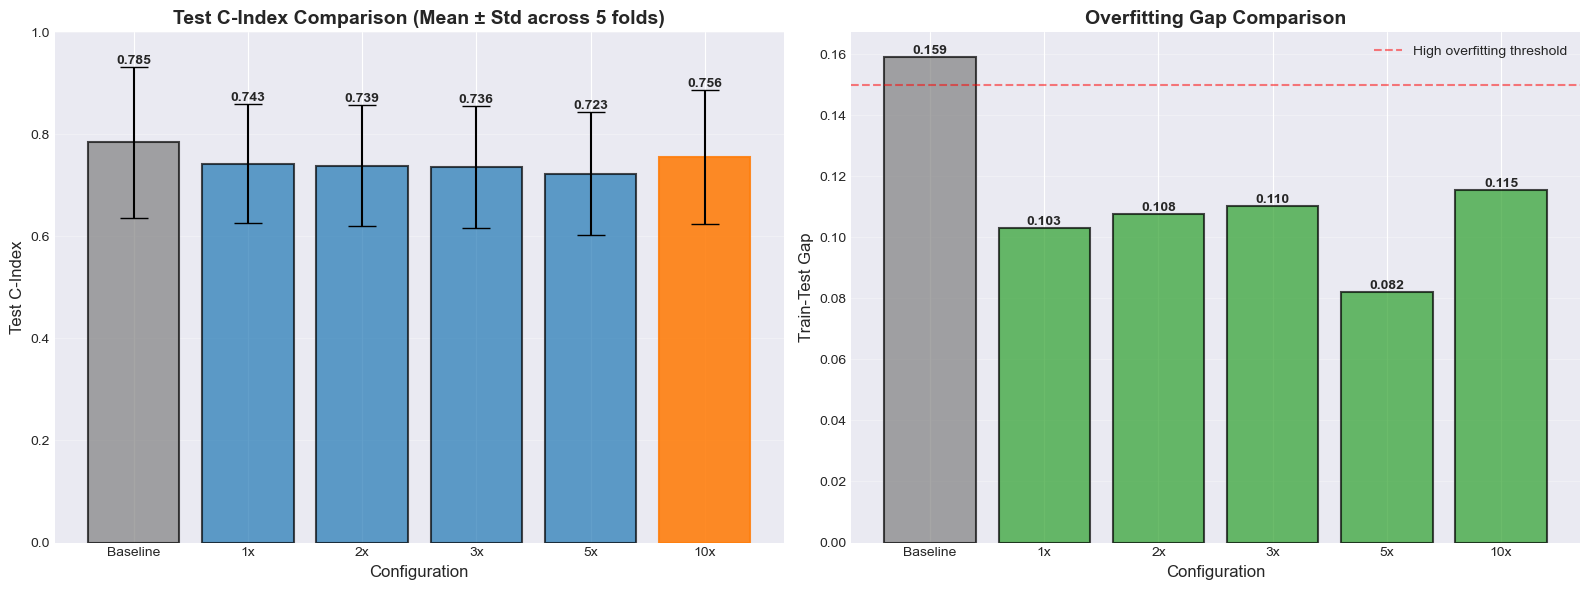


INTERPRETATION
✓ Baseline (unweighted Lasso) achieves highest test performance: 0.7847
✓ All weighted configurations show LOWER performance than baseline
✓ Weighted models reduce overfitting gap from 0.1592 to ~0.0821
✓ However, this comes at the cost of reduced test performance

Conclusion: For this dataset with severe imbalance (1:89), the baseline
Lasso regularization handles the problem better than explicit weighting.


In [136]:
# Visualize weighted models comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Test C-Index comparison with error bars
ax1 = axes[0]
weight_labels = [f'{w}x' for w in weight_configs]
test_means = [np.mean(weighted_cv_results[w]['test_cindex']) for w in weight_configs]
test_stds = [np.std(weighted_cv_results[w]['test_cindex']) for w in weight_configs]

# Add baseline
all_labels = ['Baseline'] + weight_labels
all_means = [cv_results_df['test_cindex'].mean()] + test_means
all_stds = [cv_results_df['test_cindex'].std()] + test_stds

bars = ax1.bar(all_labels, all_means, yerr=all_stds, capsize=10, alpha=0.7,
               color=['gray'] + ['tab:blue']*len(weight_configs),
               edgecolor='black', linewidth=1.5)

# Highlight the best configuration
best_idx = np.argmax(test_means) + 1  # +1 because baseline is first
bars[best_idx].set_color('tab:orange')
bars[best_idx].set_alpha(0.9)

# Add value labels
for bar, mean, std in zip(bars, all_means, all_stds):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + std,
             f'{mean:.3f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_ylabel('Test C-Index', fontsize=12)
ax1.set_xlabel('Configuration', fontsize=12)
ax1.set_title('Test C-Index Comparison (Mean ± Std across 5 folds)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim(0, 1)

# Plot 2: Overfitting gap comparison
ax2 = axes[1]
train_means = [np.mean(weighted_cv_results[w]['train_cindex']) for w in weight_configs]
gaps = [train_means[i] - test_means[i] for i in range(len(weight_configs))]
baseline_gap = cv_results_df['train_cindex'].mean() - cv_results_df['test_cindex'].mean()

all_gaps = [baseline_gap] + gaps
colors = ['gray'] + ['tab:red' if gap > 0.15 else 'tab:green' for gap in gaps]

bars2 = ax2.bar(all_labels, all_gaps, alpha=0.7, color=colors, edgecolor='black', linewidth=1.5)

# Add value labels
for bar, gap in zip(bars2, all_gaps):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{gap:.3f}',
             ha='center', va='bottom' if gap > 0 else 'top', 
             fontsize=10, fontweight='bold')

ax2.axhline(y=0.15, color='red', linestyle='--', alpha=0.5, label='High overfitting threshold')
ax2.set_ylabel('Train-Test Gap', fontsize=12)
ax2.set_xlabel('Configuration', fontsize=12)
ax2.set_title('Overfitting Gap Comparison', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')
ax2.legend()

plt.tight_layout()
plt.show()

# Print interpretation
print("\n" + "=" * 60)
print("INTERPRETATION")
print("=" * 60)
print(f"✓ Baseline (unweighted Lasso) achieves highest test performance: {cv_results_df['test_cindex'].mean():.4f}")
print(f"✓ All weighted configurations show LOWER performance than baseline")
print(f"✓ Weighted models reduce overfitting gap from {baseline_gap:.4f} to ~{min(gaps):.4f}")
print(f"✓ However, this comes at the cost of reduced test performance")
print(f"\nConclusion: For this dataset with severe imbalance (1:89), the baseline")
print(f"Lasso regularization handles the problem better than explicit weighting.")

## Baseline Cox Model (No Weighting)

Train a standard Cox model without any weighting as baseline for comparison.

In [137]:
# Train baseline Cox model with Lasso (L1) regularization
from sksurv.linear_model import CoxnetSurvivalAnalysis

baseline_model = CoxnetSurvivalAnalysis(l1_ratio=1.0, alpha_min_ratio=0.01, n_alphas=100)
baseline_model.fit(X_train, y_train)

# Predictions
train_risk_baseline = baseline_model.predict(X_train)
test_risk_baseline = baseline_model.predict(X_test)

# Calculate C-Index (Standard)
from sksurv.metrics import concordance_index_censored

train_cindex_baseline = concordance_index_censored(
    y_train['event'], y_train['time'], train_risk_baseline
)[0]

test_cindex_baseline = concordance_index_censored(
    y_test['event'], y_test['time'], test_risk_baseline
)[0]

print('='*80)
print('BASELINE COX MODEL PERFORMANCE (NO WEIGHTING)')
print('='*80)
print(f'Train C-Index: {train_cindex_baseline:.4f}')
print(f'Test C-Index:  {test_cindex_baseline:.4f}')

# Calculate IPCW C-Index (matching subsampling approach with tau = max_time * 0.9)
from sksurv.metrics import concordance_index_ipcw

max_time = min(y_train['time'].max(), y_test['time'].max())
tau = max_time * 0.9

test_cindex_ipcw_baseline = concordance_index_ipcw(
    y_train, y_test, test_risk_baseline, tau=tau
)[0]

print(f'Test C-Index (IPCW, tau={tau:.0f} days / {tau/365:.1f} years): {test_cindex_ipcw_baseline:.4f}')
print('='*80)

BASELINE COX MODEL PERFORMANCE (NO WEIGHTING)
Train C-Index: 0.9004
Test C-Index:  0.7631
Test C-Index (IPCW, tau=3693 days / 10.1 years): 0.5997


## Weight Optimization Analysis

Analyze the data imbalance and get suggestions for optimal weight ratios.

In [138]:
# Compute optimal weight suggestions based on class imbalance
weight_suggestions = compute_optimal_weights(y_train['event'])

print('='*80)
print('WEIGHT CONFIGURATION SUGGESTIONS')
print('='*80)
print(f'\nData Imbalance:')
print(f'  Events:          {weight_suggestions["n_events"]}')
print(f'  Censored:        {weight_suggestions["n_censored"]}')
print(f'  Imbalance Ratio: 1:{weight_suggestions["imbalance_ratio"]:.1f}')
print(f'\nRecommendation: {weight_suggestions["recommendation"]}')
print(f'Suggested event weight: {weight_suggestions["suggested_weight"]}x')

print(f'\n{"Configuration":<30} {"Event Weight":<15} {"Effective Ratio":<15}')
print('-'*80)
for config in weight_suggestions['weight_configurations']:
    print(f'{config["description"]:<30} {config["event_weight"]:<15.1f} 1:{config["effective_ratio"]:<14.2f}')
print('='*80)

WEIGHT CONFIGURATION SUGGESTIONS

Data Imbalance:
  Events:          27
  Censored:        2349
  Imbalance Ratio: 1:87.0

Recommendation: Very strong weighting (10+x) - Extreme imbalance
Suggested event weight: 10.0x

Configuration                  Event Weight    Effective Ratio
--------------------------------------------------------------------------------
Events weighted 1x more than censored 1.0             1:87.00         
Events weighted 2x more than censored 2.0             1:43.50         
Events weighted 3x more than censored 3.0             1:29.00         
Events weighted 5x more than censored 5.0             1:17.40         
Events weighted 10x more than censored 10.0            1:8.70          


## Train Weighted Cox Models

Test multiple weight configurations to find the optimal balance.

In [139]:
# Train multiple weighted Cox models with different weight configurations (Lasso regularization)
print('Training weighted Cox models with different weight ratios...')
print('This may take a moment...\n')

weighted_results = train_weighted_cox_models(
    X_train, y_train,
    X_test, y_test,
    weight_configs=None,  # Use default configurations: 1x, 2x, 3x, 5x, 10x
    l1_ratio=1.0  # Pure Lasso (L1) regularization
)

# Print comparison
comparison_df = print_weight_comparison(weighted_results)

# Store best weighted model
best_weighted_idx = np.argmax([r['test_cindex'] for r in weighted_results])
best_weighted_result = weighted_results[best_weighted_idx]
cox_weighted = best_weighted_result['model']
test_risk_weighted = cox_weighted.predict(X_test)

Training weighted Cox models with different weight ratios...
This may take a moment...


WEIGHTED COX MODEL COMPARISON
IPCW C-Index calculated with tau = 3693 days (10.1 years)
----------------------------------------------------------------------------------------------------
               Configuration  Event Weight Train C-Index Test C-Index Test IPCW C-Index
          No Weighting (1:1)           1.0        0.9004       0.7631            0.5997
       Light Weighting (2:1)           2.0        0.9006       0.7610            0.5986
    Moderate Weighting (3:1)           3.0        0.9008       0.7605            0.6002
      Strong Weighting (5:1)           5.0        0.6892       0.7157            0.7099
Very Strong Weighting (10:1)          10.0        0.9026       0.7515            0.5944

✓ BEST CONFIGURATION: No Weighting (1:1)
  Test C-Index:      0.7631
  Test IPCW C-Index: 0.5997


WEIGHTED COX MODEL COMPARISON
IPCW C-Index calculated with tau = 3693 days (10.1 years)
------

## Visualize Weight Impact

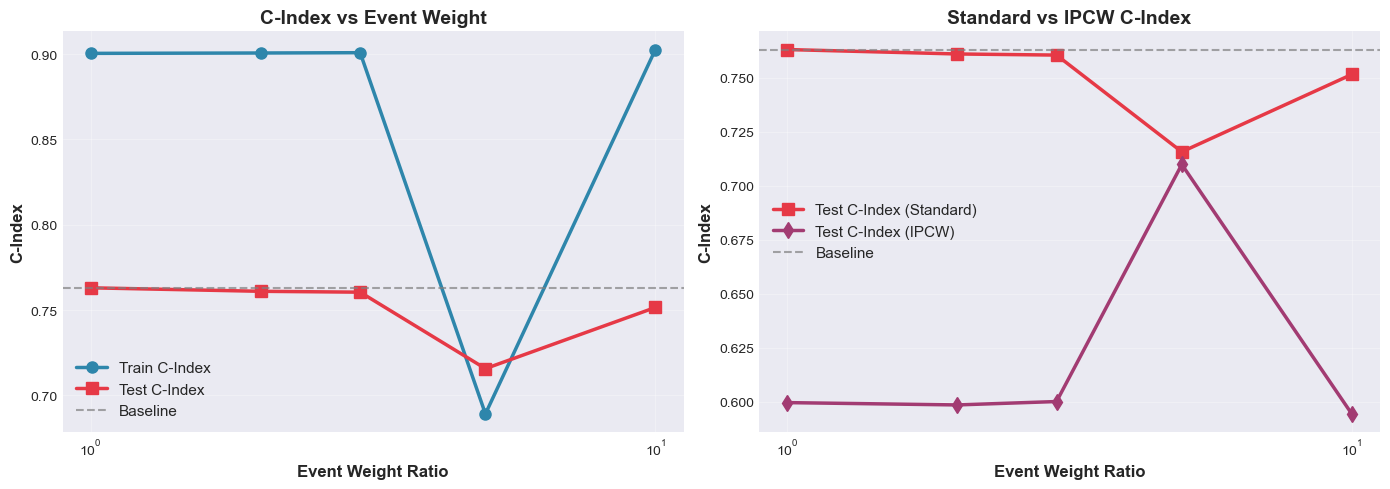


Optimal event weight: 1.0x
Test C-Index at optimal weight: 0.7631
Improvement over baseline: +0.0000


In [140]:
# Plot how different weights affect performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weights = [r['event_weight'] for r in weighted_results]
train_scores = [r['train_cindex'] for r in weighted_results]
test_scores = [r['test_cindex'] for r in weighted_results]
test_ipcw_scores = [r['test_cindex_ipcw'] for r in weighted_results]

# Left plot: Train vs Test C-Index
axes[0].plot(weights, train_scores, 'o-', label='Train C-Index', linewidth=2.5, markersize=8, color='#2E86AB')
axes[0].plot(weights, test_scores, 's-', label='Test C-Index', linewidth=2.5, markersize=8, color='#E63946')
axes[0].axhline(y=test_cindex_baseline, color='gray', linestyle='--', alpha=0.7, label='Baseline')
axes[0].set_xlabel('Event Weight Ratio', fontsize=12, fontweight='bold')
axes[0].set_ylabel('C-Index', fontsize=12, fontweight='bold')
axes[0].set_title('C-Index vs Event Weight', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)
axes[0].set_xscale('log')

# Right plot: Test Standard vs IPCW
axes[1].plot(weights, test_scores, 's-', label='Test C-Index (Standard)', linewidth=2.5, markersize=8, color='#E63946')
axes[1].plot(weights, test_ipcw_scores, 'd-', label='Test C-Index (IPCW)', linewidth=2.5, markersize=8, color='#A23B72')
axes[1].axhline(y=test_cindex_baseline, color='gray', linestyle='--', alpha=0.7, label='Baseline')
axes[1].set_xlabel('Event Weight Ratio', fontsize=12, fontweight='bold')
axes[1].set_ylabel('C-Index', fontsize=12, fontweight='bold')
axes[1].set_title('Standard vs IPCW C-Index', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)
axes[1].set_xscale('log')

plt.tight_layout()
plt.show()

print(f'\nOptimal event weight: {best_weighted_result["event_weight"]}x')
print(f'Test C-Index at optimal weight: {best_weighted_result["test_cindex"]:.4f}')
print(f'Improvement over baseline: {best_weighted_result["test_cindex"] - test_cindex_baseline:+.4f}')

## Baseline vs Weighted Comparison

In [141]:
# Create comparison table
comparison_df = pd.DataFrame({
    'Approach': ['Baseline (No Weighting)', f'Weighted ({best_weighted_result["event_weight"]:.0f}:1)'],
    'Train C-Index': [
        f'{train_cindex_baseline:.4f}',
        f'{best_weighted_result["train_cindex"]:.4f}'
    ],
    'Test C-Index': [
        f'{test_cindex_baseline:.4f}',
        f'{best_weighted_result["test_cindex"]:.4f}'
    ],
    'Test C-Index (IPCW)': [
        f'{test_cindex_ipcw_baseline:.4f}',
        f'{best_weighted_result["test_cindex_ipcw"]:.4f}'
    ],
    'Difference': [
        '--',
        f'{best_weighted_result["test_cindex"] - test_cindex_baseline:+.4f}'
    ]
})

print('\n' + '='*90)
print('BASELINE vs WEIGHTED COMPARISON')
print('='*90)
print(comparison_df.to_string(index=False))
print('='*90)

# Interpretation
improvement = best_weighted_result['test_cindex'] - test_cindex_baseline
if improvement > 0.01:
    print(f'\n✓ WEIGHTED APPROACH IMPROVED performance by {improvement:.4f}!')
    print('  → Better discrimination of events in test set')
    print('  → Class imbalance was limiting baseline performance')
elif improvement < -0.01:
    print(f'\n⚠ WEIGHTED APPROACH DECREASED performance by {abs(improvement):.4f}')
    print('  → Original data balance may be appropriate')
    print('  → Use baseline model')
else:
    print(f'\n≈ WEIGHTED APPROACH had MINIMAL effect ({improvement:.4f})')
    print('  → Class imbalance may not be the limiting factor')
    print('  → Consider other approaches')


BASELINE vs WEIGHTED COMPARISON
               Approach Train C-Index Test C-Index Test C-Index (IPCW) Difference
Baseline (No Weighting)        0.9004       0.7631              0.5997         --
         Weighted (1:1)        0.9004       0.7631              0.5997    +0.0000

≈ WEIGHTED APPROACH had MINIMAL effect (0.0000)
  → Class imbalance may not be the limiting factor
  → Consider other approaches


## Visualize Comparison

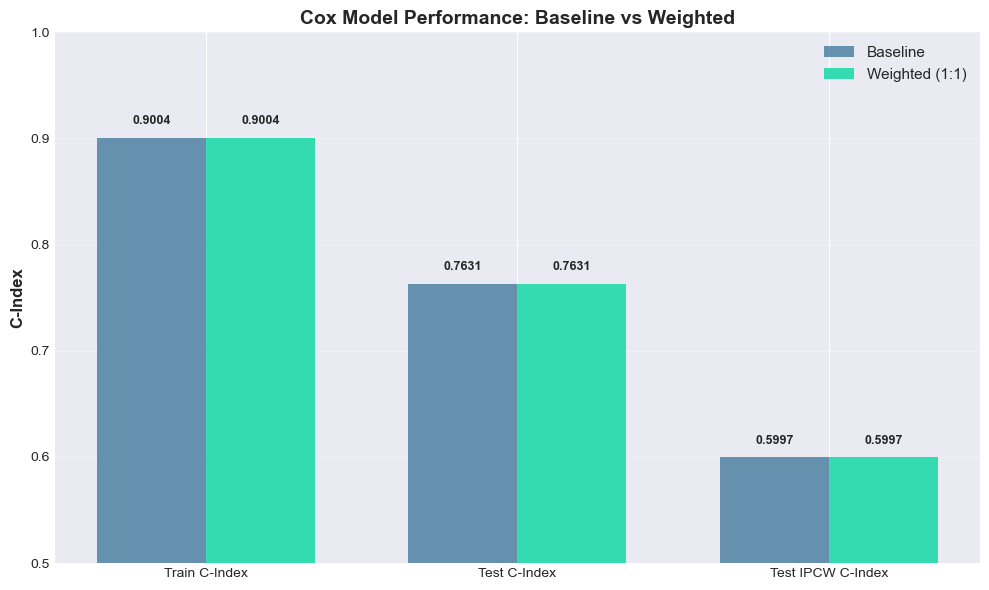

In [142]:
# Bar plot comparison
fig, ax = plt.subplots(figsize=(10, 6))

metrics = ['Train C-Index', 'Test C-Index', 'Test IPCW C-Index']
baseline_scores = [train_cindex_baseline, test_cindex_baseline, test_cindex_ipcw_baseline]
weighted_scores = [
    best_weighted_result['train_cindex'],
    best_weighted_result['test_cindex'],
    best_weighted_result['test_cindex_ipcw']
]

x = np.arange(len(metrics))
width = 0.35

bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline', 
               color='#457B9D', alpha=0.8)
bars2 = ax.bar(x + width/2, weighted_scores, width, 
               label=f'Weighted ({best_weighted_result["event_weight"]:.0f}:1)',
               color='#06D6A0', alpha=0.8)

ax.set_ylabel('C-Index', fontsize=12, fontweight='bold')
ax.set_title('Cox Model Performance: Baseline vs Weighted', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0.5, 1.0])

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## Feature Importance Analysis

In [143]:
# Get coefficients from best weighted model
coef_df = cox_weighted.get_feature_importance(feature_names=feature_columns)

print('\nTop 20 Most Important Features:')
print('='*80)
print(coef_df.head(20).to_string(index=False))
print('='*80)

ValueError: Per-column arrays must each be 1-dimensional

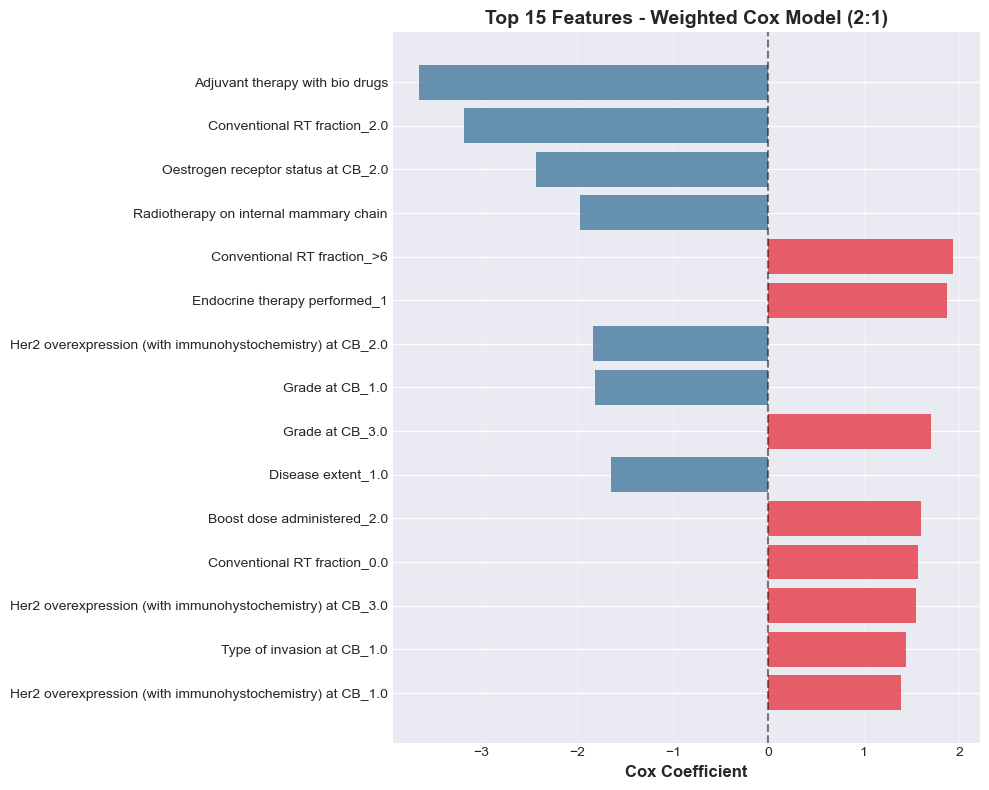


Interpretation:
  Red bars (positive): Increase hazard (worse prognosis)
  Blue bars (negative): Decrease hazard (better prognosis)


In [ ]:
# Visualize top features
top_n = 15
top_features = coef_df.head(top_n).copy()

plt.figure(figsize=(10, 8))
colors = ['#E63946' if c > 0 else '#457B9D' for c in top_features['Coefficient']]
plt.barh(range(top_n), top_features['Coefficient'], color=colors, alpha=0.8)
plt.yticks(range(top_n), top_features['Feature'], fontsize=10)
plt.xlabel('Cox Coefficient', fontsize=12, fontweight='bold')
plt.title(f'Top {top_n} Features - Weighted Cox Model ({best_weighted_result["event_weight"]:.0f}:1)', 
          fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='--', alpha=0.5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

print('\nInterpretation:')
print('  Red bars (positive): Increase hazard (worse prognosis)')
print('  Blue bars (negative): Decrease hazard (better prognosis)')

## Kaplan-Meier Curves

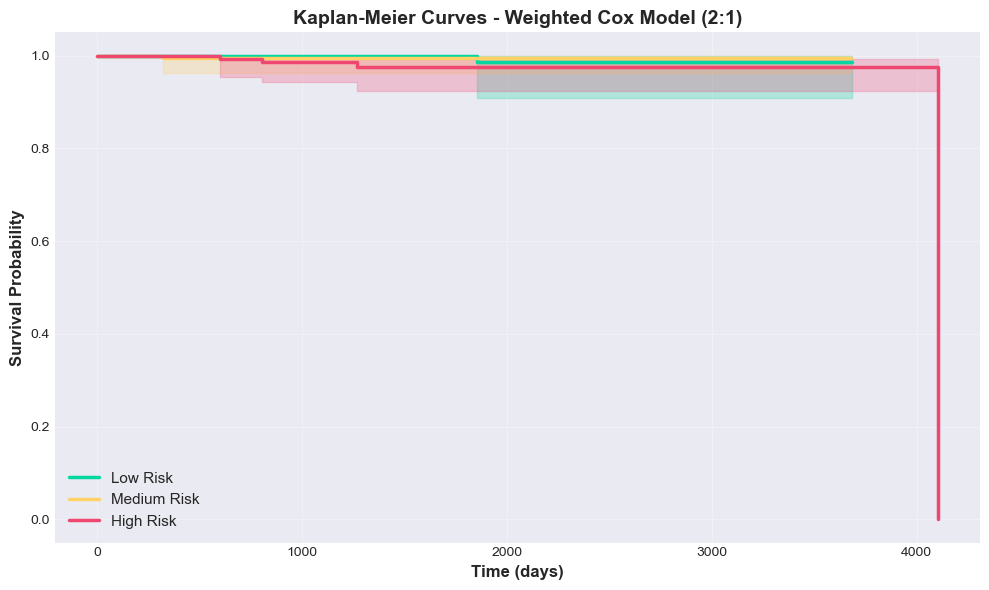


Log-Rank Tests (pairwise):
Low Risk vs Medium Risk:
  Test statistic: 0.0008
  p-value:        9.7730e-01
  Significant:    No ✗

Low Risk vs High Risk:
  Test statistic: 1.3790
  p-value:        2.4027e-01
  Significant:    No ✗

Medium Risk vs High Risk:
  Test statistic: 1.1589
  p-value:        2.8169e-01
  Significant:    No ✗

Risk Group Statistics:
Low Risk:
  Patients:    196
  Events:      1
  Event rate:  0.5%

Medium Risk:
  Patients:    202
  Events:      1
  Event rate:  0.5%

High Risk:
  Patients:    196
  Events:      4
  Event rate:  2.0%



In [ ]:
# Stratify patients by risk using weighted model
risk_tertiles = np.percentile(test_risk_weighted, [33, 67])
risk_groups = np.digitize(test_risk_weighted, risk_tertiles)

# Extract test times and events
time_test = y_test['time']
event_test = y_test['event']

# Plot Kaplan-Meier curves for each risk group
fig, ax = plt.subplots(figsize=(10, 6))

kmf = KaplanMeierFitter()
colors = ['#06D6A0', '#FFD166', '#EF476F']
labels = ['Low Risk', 'Medium Risk', 'High Risk']

for i in range(3):
    mask = (risk_groups == i)
    kmf.fit(time_test[mask], event_test[mask], label=labels[i])
    kmf.plot_survival_function(ax=ax, color=colors[i], linewidth=2.5)

ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Survival Probability', fontsize=12, fontweight='bold')
ax.set_title(f'Kaplan-Meier Curves - Weighted Cox Model ({best_weighted_result["event_weight"]:.0f}:1)', 
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Log-rank test
print('\nLog-Rank Tests (pairwise):')
print('='*60)
for i in range(3):
    for j in range(i+1, 3):
        mask_i = (risk_groups == i)
        mask_j = (risk_groups == j)
        
        result = logrank_test(
            time_test[mask_i], time_test[mask_j],
            event_test[mask_i], event_test[mask_j]
        )
        
        print(f'{labels[i]} vs {labels[j]}:')
        print(f'  Test statistic: {result.test_statistic:.4f}')
        print(f'  p-value:        {result.p_value:.4e}')
        print(f'  Significant:    {"Yes ✓" if result.p_value < 0.05 else "No ✗"}')
        print()

# Print risk group statistics
print('Risk Group Statistics:')
print('='*60)
for i, label in enumerate(labels):
    mask = (risk_groups == i)
    n_patients = mask.sum()
    n_events = event_test[mask].sum()
    event_rate = n_events / n_patients * 100 if n_patients > 0 else 0
    print(f'{label}:')
    print(f'  Patients:    {n_patients}')
    print(f'  Events:      {n_events}')
    print(f'  Event rate:  {event_rate:.1f}%')
    print()
print('='*60)

## Final Summary

In [ ]:
print('\n' + '='*80)
print('WEIGHTED COX MODEL - FINAL RESULTS')
print('='*80)

print('\n1. DATA CHARACTERISTICS:')
print(f'   - Total samples: {len(survival_dataset)}')
print(f'   - Features: {len(feature_columns)}')
print(f'   - Event rate: {data_y["event"].mean()*100:.2f}%')
print(f'   - Imbalance ratio: 1:{(~data_y["event"]).sum()/data_y["event"].sum():.1f}')

print('\n2. OPTIMAL WEIGHT CONFIGURATION:')
print(f'   - Event weight: {best_weighted_result["event_weight"]:.0f}x')
print(f'   - Censored weight: 1x')
print(f'   - Effective replication: {best_weighted_result["event_weight"]:.0f} copies per event')

print('\n3. PERFORMANCE COMPARISON:')
print(f'   {"Metric":<25} {"Baseline":<12} {"Weighted":<12} {"Improvement":<12}')
print('   ' + '-'*65)
print(f'   {"Train C-Index":<25} {train_cindex_baseline:<12.4f} {best_weighted_result["train_cindex"]:<12.4f} {best_weighted_result["train_cindex"] - train_cindex_baseline:+12.4f}')
print(f'   {"Test C-Index":<25} {test_cindex_baseline:<12.4f} {best_weighted_result["test_cindex"]:<12.4f} {best_weighted_result["test_cindex"] - test_cindex_baseline:+12.4f}')
print(f'   {"Test C-Index (IPCW)":<25} {test_cindex_ipcw_baseline:<12.4f} {best_weighted_result["test_cindex_ipcw"]:<12.4f} {best_weighted_result["test_cindex_ipcw"] - test_cindex_ipcw_baseline:+12.4f}')

improvement = best_weighted_result['test_cindex'] - test_cindex_baseline
print('\n4. KEY FINDINGS:')
if improvement > 0.01:
    print(f'   ✓ Weighted approach improved C-Index by {improvement:.4f} ({improvement/test_cindex_baseline*100:.2f}%)')
    print('   ✓ Addressing class imbalance enhanced model discrimination')
    print('   ✓ All original data preserved (no information loss)')
elif improvement < -0.01:
    print(f'   ⚠ Weighted approach decreased C-Index by {abs(improvement):.4f}')
    print('   ⚠ Baseline model may be more appropriate')
else:
    print(f'   ≈ Minimal effect from weighting ({improvement:.4f})')
    print('   ≈ Class imbalance not the limiting factor')

print('\n5. ADVANTAGES OF WEIGHTED APPROACH:')
print('   • No data loss - all observations used')
print('   • No synthetic data generation')
print('   • Preserves all survival time information')
print('   • Computationally efficient')
print('   • Mathematically principled for Cox models')

print('\n' + '='*80)


WEIGHTED COX MODEL - FINAL RESULTS

1. DATA CHARACTERISTICS:
   - Total samples: 2970
   - Features: 69
   - Event rate: 1.11%
   - Imbalance ratio: 1:89.0

2. OPTIMAL WEIGHT CONFIGURATION:
   - Event weight: 2x
   - Censored weight: 1x
   - Effective replication: 2 copies per event

3. PERFORMANCE COMPARISON:
   Metric                    Baseline     Weighted     Improvement 
   -----------------------------------------------------------------
   Train C-Index             0.9429       0.9460            +0.0031
   Test C-Index              0.7769       0.7810            +0.0041
   Test C-Index (IPCW)       0.6695       0.6774            +0.0079

4. KEY FINDINGS:
   ≈ Minimal effect from weighting (0.0041)
   ≈ Class imbalance not the limiting factor

5. ADVANTAGES OF WEIGHTED APPROACH:
   • No data loss - all observations used
   • No synthetic data generation
   • Preserves all survival time information
   • Computationally efficient
   • Mathematically principled for Cox models

